In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

data_folder = "/content/drive/MyDrive/FraudDetectionProject"
print(os.listdir(data_folder))


Mounted at /content/drive
['PS_20174392719_1491204439457_log.csv.zip', 'PS_20174392719_1491204439457_log.csv']


In [ ]:

import os

data_folder = "/content/drive/MyDrive/FraudDetectionProject"

print("Folder exists:", os.path.exists(data_folder))

if os.path.exists(data_folder):
    print("Files in folder:")
    print(os.listdir(data_folder))


Folder exists: True
Files in folder:
['PS_20174392719_1491204439457_log.csv.zip', 'PS_20174392719_1491204439457_log.csv']


In [ ]:

import zipfile
import os

data_folder = "/content/drive/MyDrive/FraudDetectionProject"

zip_path = os.path.join(
    data_folder,
    "PS_20174392719_1491204439457_log.csv.zip"
)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(data_folder)

print("ZIP file extracted successfully!")
print("Files in folder:")
print(os.listdir(data_folder))


ZIP file extracted successfully!
Files in folder:
['PS_20174392719_1491204439457_log.csv.zip', 'PS_20174392719_1491204439457_log.csv']


In [ ]:

import pandas as pd

file_path = os.path.join(
    data_folder,
    "PS_20174392719_1491204439457_log.csv"
)

df_sample = pd.read_csv(file_path, nrows=10000)

print("Dataset loaded successfully!")
print("Rows and columns:", df_sample.shape)

display(df_sample.head())


Dataset loaded successfully!
Rows and columns: (10000, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:

# Check dataset structure and data types

print("Dataset shape:", df_sample.shape)

print("\nColumn names:")
print(df_sample.columns.tolist())

print("\nData types and non-null values:")
df_sample.info()

#It checks whether amounts and balances are numeric, transaction types are text, and fraud labels are stored correctly.

Dataset shape: (10000, 11)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            10000 non-null  int64  
 1   type            10000 non-null  object 
 2   amount          10000 non-null  float64
 3   nameOrig        10000 non-null  object 
 4   oldbalanceOrg   10000 non-null  float64
 5   newbalanceOrig  10000 non-null  float64
 6   nameDest        10000 non-null  object 
 7   oldbalanceDest  10000 non-null  float64
 8   newbalanceDest  10000 non-null  float64
 9   isFraud         10000 non-null  int64  
 10  isFlaggedFraud  10000 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 859.5+ KB


In [ ]:

# Check missing values
print("Missing values per column:")
print(df_sample.isnull().sum())

# Check completely duplicated rows
print("\nNumber of completely duplicated rows:")
print(df_sample.duplicated().sum())

# Check duplicate transaction identifiers
print("\nDuplicate original account IDs:")
print(df_sample["nameOrig"].duplicated().sum())


Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Number of completely duplicated rows:
0

Duplicate original account IDs:
0


In [ ]:
# Count legitimate and fraudulent transactions
fraud_counts = df_sample["isFraud"].value_counts().sort_index()

print("Transaction counts:")
print(fraud_counts.rename(index={
    0: "Legitimate",
    1: "Fraudulent"
}))

# Calculate percentages
fraud_percentages = (
    df_sample["isFraud"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nTransaction percentages:")
print(fraud_percentages.rename(index={
   0: "Legitimate",
   1: "Fraudulent"
}).round(2))

Transaction counts:
isFraud
Legitimate    9932
Fraudulent      68
Name: count, dtype: int64

Transaction percentages:
isFraud
Legitimate    99.32
Fraudulent     0.68
Name: proportion, dtype: float64


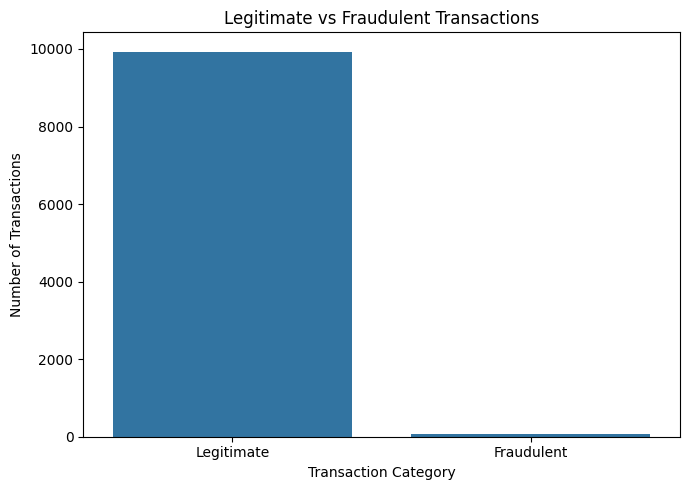

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fraud_labels = df_sample["isFraud"].map({
     0: "Legitimate",
     1: "Fraudulent"
})

plt.figure(figsize=(7,5))

sns.countplot(
   x=fraud_labels,
   order=["Legitimate", "Fraudulent"]
)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

#This chart helps you see the class imbalance visually.

In [ ]:

# Analyze fraud by transaction type

fraud_by_type = (
    df_sample.groupby("type")
    .agg(
        total_transactions=("isFraud", "size"), #number of transactions for each type.
        fraud_transactions=("isFraud", "sum"), #number labelled as fraud.
        total_amount=("amount", "sum") #sum of transaction amounts.
    )
)

fraud_by_type["fraud_rate_pct"] = (
    fraud_by_type["fraud_transactions"]
    / fraud_by_type["total_transactions"] * 100
)

fraud_by_type = fraud_by_type.sort_values(
    "fraud_rate_pct", ascending=False #percentage of transactions labelled as fraud within each type.
)

display(fraud_by_type.round(2))

,total_transactions,fraud_transactions,total_amount,fraud_rate_pct
type,,,,
TRANSFER,921,33,4.343938e+08,3.58
CASH_OUT,1321,35,2.292032e+08,2.65
CASH_IN,1949,0,3.275129e+08,0.00
DEBIT,344,0,1.230348e+06,0.00
PAYMENT,5465,0,4.312667e+07,0.00


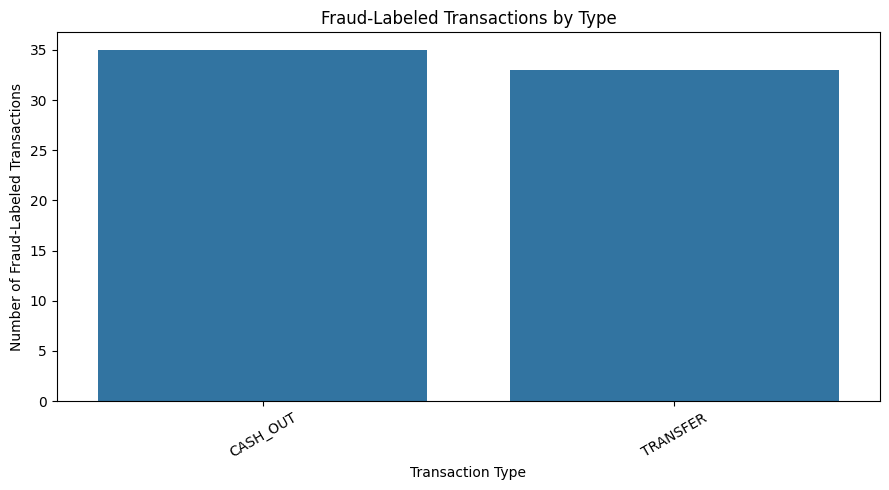

In [ ]:
from IPython.core.alias import default_aliases

import matplotlib.pyplot as plt
import seaborn as sns

fraud_only = df_sample[df_sample["isFraud"] == 1]

plt.figure(figsize=(9,5))

sns.countplot(
    data=fraud_only,
    x="type",
    order=fraud_only["type"].value_counts().index
)

plt.title("Fraud-Labeled Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud-Labeled Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#This chart shows the number of fraud-labeled transactions in each category. It does not show the fraud rate

In [ ]:
amount_summary = (
    df_sample.groupby("isFraud")["amount"]
    .agg(["count", "mean", "median", "min", "max"])
)

amount_summary.index = amount_summary.index.map({
    0: "Legitimate",
    1: "Fraudulent"
})

display(amount_summary.round(2))

#This shows the average, median, minimum, and maximum amount in each group. With only 68 fraud-labeled transactions, remember that the statistics are based on a relatively small sample.

,count,mean,median,min,max
isFraud,,,,,
Legitimate,9932,100603.24,12740.66,2.39,3776389.09
Fraudulent,68,533463.64,28644.76,181.00,10000000.00


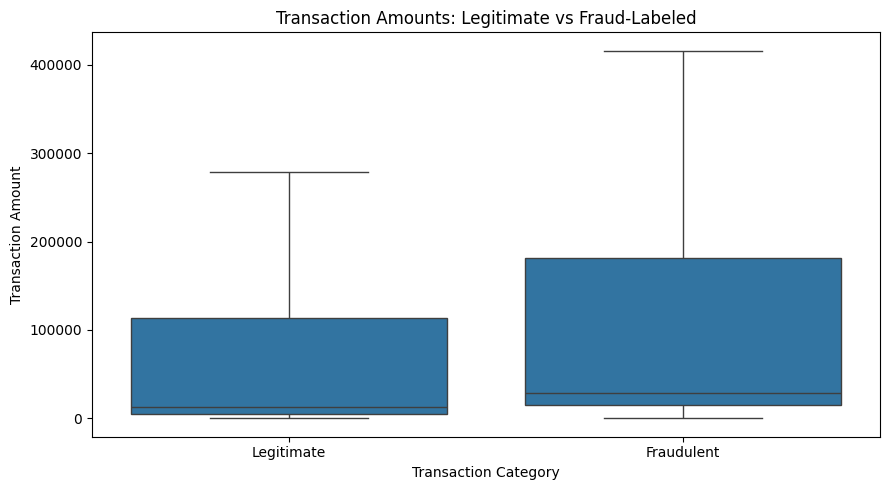

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_sample,
    x="isFraud",
    y="amount",
    showfliers=False
)

plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.title("Transaction Amounts: Legitimate vs Fraud-Labeled")
plt.xlabel("Transaction Category")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()


In [ ]:
fraud_summary = (
    df_sample.groupby("type")
    .agg(
        total_transactions=("isFraud", "count"), #Counts transactions for each type.
        fraud_transactions=("isFraud", "sum"), #Counts fraud-labeled transactions for each type
        average_amount=("amount", "mean") #Calculates the average transaction amount.
    )
    .reset_index()
)

fraud_summary["fraud_rate_pct"] = (
    fraud_summary["fraud_transactions"]
    / fraud_summary["total_transactions"] * 100 #Caulates the fraud rate as a percentage.
)

display(fraud_summary.round(2))

,type,total_transactions,fraud_transactions,average_amount,fraud_rate_pct
0,CASH_IN,1949,0,168041.49,0.00
1,CASH_OUT,1321,35,173507.34,2.65
2,DEBIT,344,0,3576.59,0.00
3,PAYMENT,5465,0,7891.43,0.00
4,TRANSFER,921,33,471654.52,3.58


In [ ]:
# Create rule-based fraud predictions

df_sample["rule_flag"] = (
    (df_sample["type"].isin(["Transfer", "CASH_OUT"])) &
    (df_sample["amount"] >= 200000)
).astype(int)

#Compare predictions with actual fraud labels
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(df_sample["isFraud"],df_sample["rule_flag"]))

print("\nClassification Report:")
print(
    classification_report(
        df_sample["isFraud"],
        df_sample["rule_flag"],
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)

print("\nNumber of transactions flagged:")
print(df_sample["rule_flag"].value_counts())

Confusion Matrix:
[[9528  404]
 [  59    9]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      0.96      0.98      9932
  Fraudulent       0.02      0.13      0.04        68

    accuracy                           0.95     10000
   macro avg       0.51      0.55      0.51     10000
weighted avg       0.99      0.95      0.97     10000


Number of transactions flagged:
rule_flag
0    9587
1     413
Name: count, dtype: int64


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

for threshold in [10000, 25000, 50000, 100000, 200000, 500000]:
    predictions = (
        df_sample["type"].isin(["TRANSFER", "CASH_OUT"]) &
        (df_sample["amount"] >= threshold)
    ).astype(int)

    results.append({
        "amount_threshold": threshold,
        "transactions_flagged": int(predictions.sum()),
        "true_fraud_detected": int(
            ((predictions == 1) & (df_sample["isFraud"] == 1)).sum()
        ),
        "false_alarms": int(
            ((predictions == 1) & (df_sample["isFraud"] == 0)).sum()
        ),
        "precision": precision_score(
            df_sample["isFraud"], predictions, zero_division=0
        ),
        "recall": recall_score(
            df_sample["isFraud"], predictions, zero_division=0
        ),
        "f1_score": f1_score(
            df_sample["isFraud"], predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1_score": "{:.2%}"
    })
)

,amount_threshold,transactions_flagged,true_fraud_detected,false_alarms,precision,recall,f1_score
0,10000,2166,64,2102,2.95%,94.12%,5.73%
1,25000,2040,40,2000,1.96%,58.82%,3.80%
2,50000,1849,28,1821,1.51%,41.18%,2.92%
3,100000,1510,22,1488,1.46%,32.35%,2.79%
4,200000,956,17,939,1.78%,25.00%,3.32%
5,500000,321,10,311,3.12%,14.71%,5.14%


In [ ]:
# Find fraud-labeled transactions missed by the rule

threshold = 10000

predictions = (
    df_sample["type"].isin(["TRANSFER", "CASH_OUT"]) &
    (df_sample["amount"] >= threshold)
).astype(int)

missed_fraud = df_sample[
    (df_sample["isFraud"] == 1) &
    (predictions == 0)
]

print("Number of missed fraud-labeled transactions:", len(missed_fraud))

display(
    missed_fraud[
        ["step", "type", "amount", "oldbalanceOrg",
         "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
    ]
)

Number of missed fraud-labeled transactions: 4


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
2,1,TRANSFER,181.0,181.0,0.0,0.0,0.0,1
3,1,CASH_OUT,181.0,181.0,0.0,21182.0,0.0,1
251,1,TRANSFER,2806.0,2806.0,0.0,0.0,0.0,1
252,1,CASH_OUT,2806.0,2806.0,0.0,26202.0,0.0,1


In [ ]:
#Create balance-based features

df_sample["origin_balance_change"] = (
    df_sample["oldbalanceOrg"] - df_sample["newbalanceOrig"]
)

df_sample["balance_amount_difference"] = (
    df_sample["origin_balance_change"] - df_sample["amount"]
).abs()

df_sample["origin_balance_zero"] = (
    df_sample["newbalanceOrig"] == 0
).astype(int)

print("Balance features created successfully!")

display(
    df_sample[
        [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "origin_balance_change", #it means how much the sender's recorded balance decreased.
        "balance_amount_difference", #it means how closely that decrease matches the transaction amount.
        "origin_balance_zero", #it means whether the sender's new balance is zero.
        "isFraud"
        ]
    ].head(10)
)

Balance features created successfully!


,type,amount,oldbalanceOrg,newbalanceOrig,origin_balance_change,balance_amount_difference,origin_balance_zero,isFraud
0,PAYMENT,9839.64,170136.00,160296.36,9839.64,1.455192e-11,0,0
1,PAYMENT,1864.28,21249.00,19384.72,1864.28,1.136868e-12,0,0
2,TRANSFER,181.00,181.00,0.00,181.00,0.000000e+00,1,1
3,CASH_OUT,181.00,181.00,0.00,181.00,0.000000e+00,1,1
4,PAYMENT,11668.14,41554.00,29885.86,11668.14,0.000000e+00,0,0
5,PAYMENT,7817.71,53860.00,46042.29,7817.71,9.094947e-13,0,0
6,PAYMENT,7107.77,183195.00,176087.23,7107.77,1.091394e-11,0,0
7,PAYMENT,7861.64,176087.23,168225.59,7861.64,1.364242e-11,0,0
8,PAYMENT,4024.36,2671.00,0.00,2671.00,1.353360e+03,1,0
9,DEBIT,5337.77,41720.00,36382.23,5337.77,3.637979e-12,0,0


In [ ]:
# Compare balance features by fraud label

balance_comparison = (
    df_sample.groupby("isFraud")
    .agg(
        transaction_count=("amount", "count"),
        average_amount=("amount", "mean"),
        average_balance_change=("origin_balance_change", "mean"),
        average_balance_difference=("balance_amount_difference", "mean"),
        zero_ending_balance_count=("origin_balance_zero", "sum")
    )
    .reset_index()
)

balance_comparison["isFraud"] = balance_comparison["isFraud"].map({
    0: "Legitimate",
    1: "Fraudulent"
})

display(balance_comparison.round(2))

,isFraud,transaction_count,average_amount,average_balance_change,average_balance_difference,zero_ending_balance_count
0,Legitimate,9932,100603.24,-25084.76,125687.99,3997
1,Fraudulent,68,533463.64,525458.57,8005.07,67


In [ ]:
# Prepare data and train a Decision Tree

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Select input features and target
X = df_sample[
    [
        "type",
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "oldbalanceDest",
        "newbalanceDest"
    ]
]

y = df_sample["isFraud"]

# Split before training to keep a separate test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Encode transaction type and keep numeric features
preprocessor = ColumnTransformer(
    transformers=[
        ("type", OneHotEncoder(handle_unknown="ignore"), ["type"]),
        (
            "numbers",
            "passthrough",
            [
                "amount",
                "oldbalanceOrg",
                "newbalanceOrig",
                "oldbalanceDest",
                "newbalanceDest"
            ]
        )
    ]
)

# Build a tree with limited depth to reduce overfitting
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Train the model
model.fit(X_train, y_train)

# Evaluate on unseen test rows
y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)

Confusion Matrix:
[[2400   83]
 [   2   15]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.98      2483
  Fraudulent       0.15      0.88      0.26        17

    accuracy                           0.97      2500
   macro avg       0.58      0.92      0.62      2500
weighted avg       0.99      0.97      0.98      2500



In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Rule-based predictions on the same test rows
X_test_original = X_test

rule_predictions = (
    X_test_original["type"].isin(["TRANSFER", "CASH_OUT"]) &
    (X_test_original["amount"] >= 200000)
).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Rule-Based (200000 threshold)",
        "Precision": precision_score(
            y_test, rule_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, rule_predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, rule_predictions, zero_division=0
        )
    },
    {
        "Model": "Decision Tree",
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }
])

for column in ["Precision", "Recall", "F1 Score"]:
    comparison[column] = (comparison[column] * 100).round(2)

display(comparison)

#A model is not automatically better just because it uses machine learning. We'll compare its precision, recall, and F1-score against the rule on identical test rows.

,Model,Precision,Recall,F1 Score
0,Rule-Based (200000 threshold),1.57,23.53,2.95
1,Decision Tree,15.31,88.24,26.09


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Build the Random Forest model
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=8,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train on the same training data
rf_model.fit(X_train, y_train)

# Evaluate on the same unseen test data
rf_pred = rf_model.predict(X_test)

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nRandom Forest Classification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Legitimate", "Fraudulent"],
        zero_division=0
    )
)

print("\nRandom Forest Summary:")
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, rf_pred, zero_division=0) * 100, 2), "%")

Random Forest Confusion Matrix:
[[2479    4]
 [   4   13]]

Random Forest Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      2483
  Fraudulent       0.76      0.76      0.76        17

    accuracy                           1.00      2500
   macro avg       0.88      0.88      0.88      2500
weighted avg       1.00      1.00      1.00      2500


Random Forest Summary:
Precision: 76.47 %
Recall: 76.47 %
F1 Score: 76.47 %


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

models = {
    "Rule-Based": rule_predictions,
    "Decision Tree": y_pred,
    "Random Forest": rf_pred
}

comparison_results = []

for model_name, predictions in models.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    comparison_results.append({
        "Model": model_name,
        "Precision (%)": round(
            precision_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, predictions, zero_division=0) * 100, 2
        ),
        "True Positives": int(tp),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "True Negatives": int(tn)
    })

final_comparison = pd.DataFrame(comparison_results)

display(final_comparison)

#This uses the same held-out test set for all three approaches, so their results are comparable.

,Model,Precision (%),Recall (%),F1 Score (%),True Positives,False Positives,False Negatives,True Negatives
0,Rule-Based,1.57,23.53,2.95,4,250,13,2233
1,Decision Tree,15.31,88.24,26.09,15,83,2,2400
2,Random Forest,76.47,76.47,76.47,13,4,4,2479


In [ ]:
import os
import joblib

#Create a folder for project output in Google Drive
output_folder = (
    "/content/drive,MyDrive/FraudDetectionProject/models"
)
os.makedirs(output_folder, exist_ok=True)

# Save the trained model
model_path = os.path.join(
    output_folder,
    "fraud_random_forest_model.pkl"
)

joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

#Creates a models folder inside your project directory in Google Drive.
#Saves the trained Random Forest, including its preprocessing pipeline.

Model saved successfully!
Saved location: /content/drive,MyDrive/FraudDetectionProject/models/fraud_random_forest_model.pkl


In [ ]:
import joblib

loaded_model = joblib.load(model_path)

print("Model loaded successully!")

#Test one transaction from the test set
sample_transaction = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_transaction)[0]
probability = loaded_model.predict_proba(sample_transaction)[0][1]

print("Predicted class:", "Fraud Alert" if prediction == 1 else "Likely Legitimate")
print("Estimated fraud probability:", round(probability * 100, 2), "%")

Model loaded successully!
Predicted class: Likely Legitimate
Estimated fraud probability: 0.0 %


In [ ]:
def predict_transaction(
    transaction_type,
    amount,
    oldbalanceOrg,
    newbalanceOrig,
    oldbalanceDest,
    newbalanceDest
):
    transaction = pd.DataFrame([{
        "type": transaction_type,
        "amount": amount,
        "oldbalanceOrg": oldbalanceOrg,
        "newbalanceOrig": newbalanceOrig,
        "oldbalanceDest": oldbalanceDest,
        "newbalanceDest": newbalanceDest
    }])

    prediction = loaded_model.predict(transaction)[0]
    probability = loaded_model.predict_proba(transaction)[0][1]

    print("Transaction Type:", transaction_type)
    print("Transaction Amount:", amount)
    print(
        "Prediction:",
        "FRAUD ALERT" if prediction == 1
        else "LIKELY LEGITIMATE"
    )
    print(
        "Estimated Fraud Probability:",
        round(probability * 100, 2), "%"
    )

In [ ]:
predict_transaction(
    transaction_type="TRANSFER",
    amount=250000,
    oldbalanceOrg=300000,
    newbalanceOrig=50000,
    oldbalanceDest=100000,
    newbalanceDest=350000
)

#This sends a sample transaction to your trained Random Forest model.

Transaction Type: TRANSFER
Transaction Amount: 250000
Prediction: LIKELY LEGITIMATE
Estimated Fraud Probability: 0.98 %


In [ ]:
predict_transaction(
    transaction_type="TRANSFER",
    amount=1000000,
    oldbalanceOrg=1000000,
    newbalanceOrig=0,
    oldbalanceDest=500000,
    newbalanceDest=1500000
)

#This tests a larger transfer where the sender's ending balance is zero.

Transaction Type: TRANSFER
Transaction Amount: 1000000
Prediction: LIKELY LEGITIMATE
Estimated Fraud Probability: 8.46 %


In [ ]:

test_transactions = pd.DataFrame([
    {
        "type": "TRANSFER",
        "amount": 500000,
        "oldbalanceOrg": 500000,
        "newbalanceOrig": 0,
        "oldbalanceDest": 100000,
        "newbalanceDest": 600000
    },
    {
        "type": "CASH_OUT",
        "amount": 300000,
        "oldbalanceOrg": 400000,
        "newbalanceOrig": 100000,
        "oldbalanceDest": 200000,
        "newbalanceDest": 500000
    },
    {
        "type": "PAYMENT",
        "amount": 5000,
        "oldbalanceOrg": 10000,
        "newbalanceOrig": 5000,
        "oldbalanceDest": 0,
        "newbalanceDest": 5000
    }
])

test_transactions["prediction"] = loaded_model.predict(
    test_transactions
)

test_transactions["fraud_probability_pct"] = (
    loaded_model.predict_proba(test_transactions)[:, 1] * 100
).round(2)

test_transactions["prediction"] = (
    test_transactions["prediction"]
    .map({0: "LIKELY LEGITIMATE", 1: "FRAUD ALERT"})
)

display(test_transactions)

#This will display three predictions in a table. These are illustrative tests using simulated transaction data, not proof that any transaction is genuinely fraudulent.

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,prediction,fraud_probability_pct
0,TRANSFER,500000,500000,0,100000,600000,LIKELY LEGITIMATE,5.53
1,CASH_OUT,300000,400000,100000,200000,500000,LIKELY LEGITIMATE,0.00
2,PAYMENT,5000,10000,5000,0,5000,LIKELY LEGITIMATE,0.00


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

transaction_type_input = widgets.Dropdown(
    options=["TRANSFER", "CASH_OUT", "CASH_IN", "PAYMENT", "DEBIT"],
    value="TRANSFER",
    description="Type:"
)

amount_input = widgets.FloatText(
    value=250000,
    description="Amount:"
)

old_origin_input = widgets.FloatText(
    value=300000,
    description="Old sender balance:"
)

new_origin_input = widgets.FloatText(
    value=50000,
    description="New sender balance:"
)

old_dest_input = widgets.FloatText(
    value=100000,
    description="Old receiver balance:"
)

new_dest_input = widgets.FloatText(
    value=350000,
    description="New receiver balance:"
)

predict_button = widgets.Button(
    description="Check Transaction",
    button_style="primary"
)

output = widgets.Output()

def on_predict_clicked(button):
    with output:
        clear_output(wait=True)

        transaction = pd.DataFrame([{
            "type": transaction_type_input.value,
            "amount": amount_input.value,
            "oldbalanceOrg": old_origin_input.value,
            "newbalanceOrig": new_origin_input.value,
            "oldbalanceDest": old_dest_input.value,
            "newbalanceDest": new_dest_input.value
        }])

        prediction = loaded_model.predict(transaction)[0]
        probability = loaded_model.predict_proba(transaction)[0][1]

        print("TRANSACTION ANALYSIS")
        print("--------------------")
        print("Type:", transaction_type_input.value)
        print("Amount:", f"{amount_input.value:,.2f}")
        print(
            "Prediction:",
            "FRAUD ALERT" if prediction == 1
            else "LIKELY LEGITIMATE"
        )
        print("Estimated fraud probability:", f"{probability:.2%}")
        print("\nThis is a model estimate, not a verified fraud determination.")

predict_button.on_click(on_predict_clicked)

display(widgets.VBox([
    transaction_type_input,
    amount_input,
    old_origin_input,
    new_origin_input,
    old_dest_input,
    new_dest_input,
    predict_button,
    output
]))

#This is an interactive demonstration of simulated transaction scoring, not a connection to a live banking system.


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

model_results = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Accuracy (%)": accuracy_score(y_test, model.predict(X_test)) * 100, #The percentage of all transactions classified correctly; it can be misleading when fraud cases are rare.
        "Precision (%)": precision_score(y_test, model.predict(X_test), zero_division=0) * 100, #Precision is the transactions flagged as fraud
        "Recall (%)": recall_score(y_test, model.predict(X_test), zero_division=0) * 100, #Recall is the fraud-labeled transactions
        "F1 Score (%)": f1_score(y_test, model.predict(X_test), zero_division=0) * 100 #A combined measure of precision and recall.
    },
    {
        "Model": "Random Forest",
        "Accuracy (%)": accuracy_score(y_test, rf_model.predict(X_test)) * 100,
        "Precision (%)": precision_score(y_test, rf_model.predict(X_test), zero_division=0) * 100,
        "Recall (%)": recall_score(y_test, rf_model.predict(X_test), zero_division=0) * 100,
        "F1 Score (%)": f1_score(y_test, rf_model.predict(X_test), zero_division=0) * 100
    }
])

display(model_results.round(2))


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Decision Tree,96.60,15.31,88.24,26.09
1,Random Forest,99.68,76.47,76.47,76.47


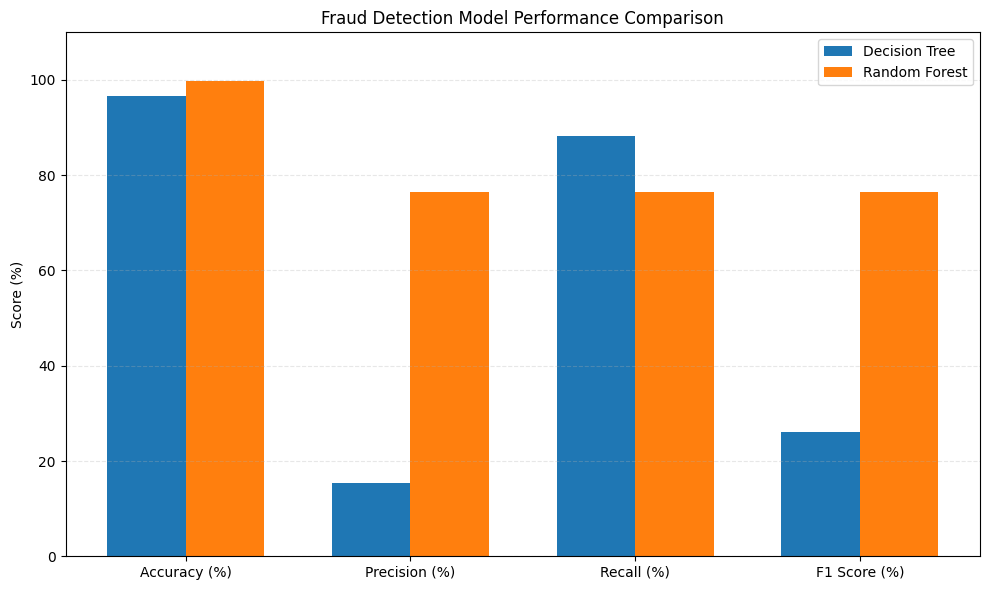

Model comparison chart saved successfully!


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1 Score (%)"]

decision_tree_scores = [96.60, 15.31, 88.24, 26.09]
random_forest_scores = [99.68, 76.47, 76.47, 76.47]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    decision_tree_scores,
    width,
    label="Decision Tree"
)

plt.bar(
    x + width / 2,
    random_forest_scores,
    width,
    label="Random Forest"
)

plt.title("Fraud Detection Model Performance Comparison")
plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/FraudDetectionProject/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")


In [ ]:

project_summary = """
PROJECT: Financial Fraud Detection Using Machine Learning

1. PROJECT OBJECTIVE
Analyze simulated financial transactions and build a machine
learning model to identify transactions labeled as fraudulent.

2. DATASET
Source: PaySim financial transaction simulation dataset
Sample analyzed: 10,000 transactions
Total features: 11
Fraud-labeled transactions: 68
Legitimate-labeled transactions: 9,932

3. DATA ANALYSIS
- Fraud-labeled transactions represented 0.68% of the sample.
- In this sample, fraud-labeled transactions occurred in
  TRANSFER and CASH_OUT transaction types.
- Transaction amounts and account balance changes were analyzed.

4. MODELS DEVELOPED
- Rule-Based Detection
- Decision Tree Classifier
- Random Forest Classifier

5. MODEL COMPARISON
Decision Tree:
Accuracy: 96.60%
Precision: 15.31%
Recall: 88.24%
F1 Score: 26.09%

Random Forest:
Accuracy: 99.68%
Precision: 76.47%
Recall: 76.47%
F1 Score: 76.47%

6. INTERACTIVE DEMO
An interactive dashboard was created in Google Colab to
enter transaction details and view model predictions.

7. CONCLUSION
The Random Forest model achieved the strongest balance
of precision and recall among the two trained models
on the current test split.

IMPORTANT LIMITATION
The dataset contains simulated transactions. The evaluation
used a 10,000-row sample and only 17 fraud-labeled cases
in the test set. Results are preliminary and do not establish
performance on real banking transactions or live systems.
"""

summary_path = (
    "/content/drive/MyDrive/FraudDetectionProject/"
    "project_summary.txt"
)

with open(summary_path, "w", encoding="utf-8") as file:
    file.write(project_summary.strip())

print("Project summary saved successfully!")
print("File location:", summary_path)


Project summary saved successfully!
File location: /content/drive/MyDrive/FraudDetectionProject/project_summary.txt


In [ ]:

import os

project_folder = "/content/drive/MyDrive/FraudDetectionProject"

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        file_path = os.path.join(root, file)
        file_size_kb = os.path.getsize(file_path) / 1024
        print(f"{indent}    {file} ({file_size_kb:.1f} KB)")

#It lists the files inside your project folder, including the saved model, chart, dataset, and summary if they are present

FraudDetectionProject/
    PS_20174392719_1491204439457_log.csv.zip (182017.1 KB)
    PS_20174392719_1491204439457_log.csv (481967.6 KB)
    model_comparison.png (107.5 KB)
    project_summary.txt (1.4 KB)


In [ ]:

import os

model_path = (
    "/content/drive/MyDrive/FraudDetectionProject/"
    "models/fraud_random_forest_model.pkl"
)

if os.path.exists(model_path):
    print("Saved model found!")
    print("File size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Saved model not found at the expected location.")
    print("Checking the project folder...")

    for root, dirs, files in os.walk(
        "/content/drive/MyDrive/FraudDetectionProject"
    ):
        for file in files:
            if file.endswith(".pkl"):
                print(os.path.join(root, file))


Saved model not found at the expected location.
Checking the project folder...


In [ ]:

import os
import joblib

model_folder = (
    "/content/drive/MyDrive/FraudDetectionProject/models"
)

os.makedirs(model_folder, exist_ok=True)

model_path = os.path.join(
    model_folder,
    "fraud_random_forest_model.pkl"
)

joblib.dump(loaded_model, model_path)

print("Model saved successfully!")
print("Model path:", model_path)
print(
    "Model size:",
    round(os.path.getsize(model_path) / (1024 * 1024), 2),
    "MB"
)

#This saves the model that you already loaded and tested.

Model saved successfully!
Model path: /content/drive/MyDrive/FraudDetectionProject/models/fraud_random_forest_model.pkl
Model size: 0.47 MB


In [ ]:

import joblib
import os

saved_model_path = (
    "/content/drive/MyDrive/FraudDetectionProject/"
    "models/fraud_random_forest_model.pkl"
)

verified_model = joblib.load(saved_model_path)

print("Model file exists:", os.path.exists(saved_model_path))
print("Model loaded successfully!")

# Test the saved model with one transaction
test_transaction = X_test.iloc[[0]]

test_prediction = verified_model.predict(test_transaction)[0]
test_probability = verified_model.predict_proba(test_transaction)[0][1]

print(
    "Prediction:",
    "FRAUD ALERT" if test_prediction == 1
    else "LIKELY LEGITIMATE"
)
print("Estimated fraud probability:", round(test_probability * 100, 2), "%")

#This confirms that the file can be loaded and used to make a prediction.

Model file exists: True
Model loaded successfully!
Prediction: LIKELY LEGITIMATE
Estimated fraud probability: 0.0 %


In [ ]:

import os

project_folder = "/content/drive/MyDrive/FraudDetectionProject"
os.makedirs(project_folder, exist_ok=True)

readme_content = """
# Financial Fraud Detection Using Machine Learning

## Project Overview
This project analyzes simulated financial transactions and
builds machine learning models to identify transactions
labeled as potentially fraudulent.

The project compares rule-based detection, a Decision Tree,
and a Random Forest classifier, and includes an interactive
transaction prediction dashboard built in Google Colab.

## Objectives
- Explore financial transaction patterns.
- Analyze fraud-label distribution and transaction types.
- Engineer features using account balance changes.
- Train and compare machine learning classifiers.
- Build an interactive transaction scoring demonstration.

## Dataset
PaySim simulated financial transaction dataset.

The analysis uses a 10,000-row sample containing 11 columns:
- Transaction type and amount
- Sender and receiver account balances
- Fraud label and other transaction attributes

Dataset source:
https://www.kaggle.com/datasets/ealaxi/paysim1

## Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- Joblib
- Google Colab
- Jupyter Notebook

## Models Compared

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---:|---:|---:|---:|
| Decision Tree | 96.60% | 15.31% | 88.24% | 26.09% |
| Random Forest | 99.68% | 76.47% | 76.47% | 76.47% |

These metrics are from the current test split. The test set
contains only 17 fraud-labeled cases, so the results are
preliminary and have substantial uncertainty.

## Key Findings
- Fraud-labeled transactions represented 0.68% of the sample.
- In this sample, fraud labels appeared in TRANSFER and
  CASH_OUT transactions.
- Random Forest achieved a stronger balance of precision
  and recall than the Decision Tree on this test split.
- Accuracy alone is insufficient for evaluating fraud
  detection because the classes are imbalanced.

## Interactive Demonstration
The Google Colab dashboard accepts transaction details and
returns a model prediction and estimated fraud probability.

This is a simulated demonstration, not a live banking system.

## Limitations
- The dataset is simulated, not real banking transaction data.
- Analysis was performed on a 10,000-row sample.
- Only 17 fraud-labeled cases were present in the test set.
- Results do not establish performance on real-world data.
- Predictions should not be treated as verified fraud findings.

## Future Improvements
- Evaluate the model on a larger dataset.
- Use cross-validation and more extensive model tuning.
- Analyze precision-recall curves and probability calibration.
- Build a web interface for the demonstration.
- Test generalization on suitable independent data.

## Author
Data Analytics Portfolio Project
"""

readme_path = os.path.join(project_folder, "README.md")

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README.md created successfully!")
print("Location:", readme_path)


README.md created successfully!
Location: /content/drive/MyDrive/FraudDetectionProject/README.md


In [ ]:

import os

project_folder = "/content/drive/MyDrive/FraudDetectionProject"

required_files = [
    "README.md",
    "project_summary.txt",
    "model_comparison.png",
    "models/fraud_random_forest_model.pkl"
]

print("PROJECT FILE CHECK")
print("------------------")

for file in required_files:
    full_path = os.path.join(project_folder, file)

    if os.path.exists(full_path):
        size_kb = os.path.getsize(full_path) / 1024
        print(f"FOUND: {file} ({size_kb:.1f} KB)")
    else:
        print(f"MISSING: {file}")


PROJECT FILE CHECK
------------------
FOUND: README.md (2.6 KB)
FOUND: project_summary.txt (1.4 KB)
FOUND: model_comparison.png (107.5 KB)
FOUND: models/fraud_random_forest_model.pkl (485.0 KB)


In [ ]:

from google.colab import files

files.download(
    "/content/drive/MyDrive/FraudDetectionProject/README.md"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

files.download(
    "/content/drive/MyDrive/FraudDetectionProject/project_summary.txt"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

files.download(
    "/content/drive/MyDrive/FraudDetectionProject/model_comparison.png"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>